# 01 - Exploração dos dados

Pergunta do projeto: um LLM sem treino classifica avaliações de clientes melhor que um modelo clássico de machine learning?

Aqui só olho para os dados (avaliações de clientes do Olist, loja online brasileira) antes de modelar.

In [1]:
import re
from collections import Counter

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from reviews.preparo import carregar_bruto, preparar

sns.set_theme(style="whitegrid")
bruto = carregar_bruto()
print(bruto.shape)
bruto.head(3)

(99224, 7)


,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18 00:00:00,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10 00:00:00,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17 00:00:00,2018-02-18 14:36:24


## 1. Distribuição das notas (todas as avaliações)

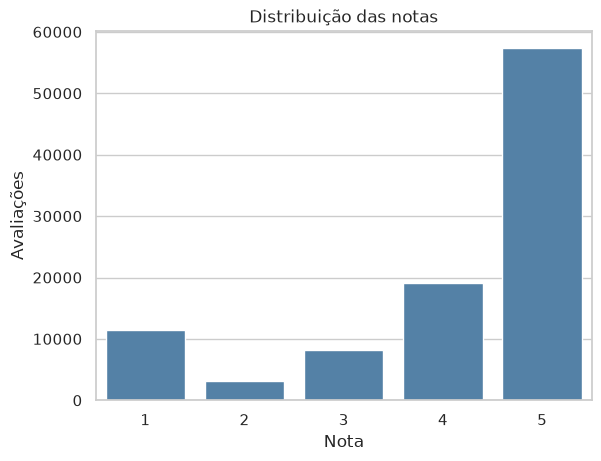

review_score
1    0.115
2    0.032
3    0.082
4    0.193
5    0.578
Name: proportion, dtype: float64


In [2]:
ax = sns.countplot(data=bruto, x="review_score", color="steelblue")
ax.set(title="Distribuição das notas", xlabel="Nota", ylabel="Avaliações")
plt.show()
print(bruto["review_score"].value_counts(normalize=True).sort_index().round(3))

**Conclusão:** as notas são muito concentradas nos extremos: 58% são nota 5 e 11,5% nota 1. A nota 3 é pouco frequente (8%).

## 2. Quantas avaliações têm texto?

Só dá para classificar texto onde o cliente escreveu um comentário (`review_comment_message`).

Com texto: 40977 de 99224 (41.3%)


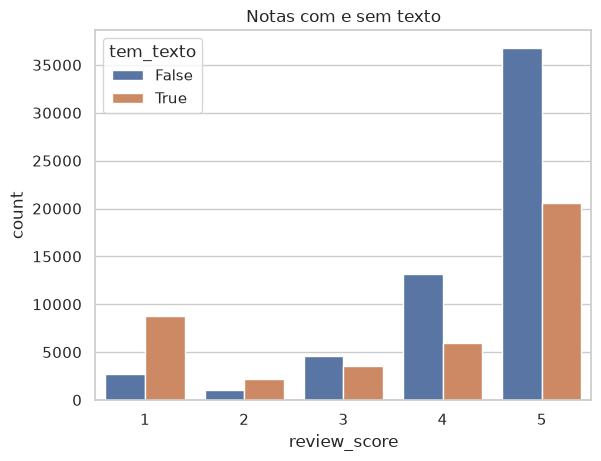

In [3]:
com_texto = bruto["review_comment_message"].notna()
print(f"Com texto: {com_texto.sum()} de {len(bruto)} ({com_texto.mean():.1%})")
sns.countplot(data=bruto.assign(tem_texto=com_texto), x="review_score", hue="tem_texto")
plt.title("Notas com e sem texto")
plt.show()

**Conclusão:** só 41% das avaliações têm comentário, então o conjunto de trabalho é bem menor que o arquivo original.

## 3. Rótulos e a nota 3

Para a pergunta "positivo ou negativo?" uso: notas 1-2 = negativo e notas 4-5 = positivo. **A nota 3 fica de fora da comparação principal** porque é ambígua: um comentário nota 3 pode ser elogio com ressalva ou crítica leve, e nem uma pessoa decidiria com segurança. Incluí-la misturaria erro do modelo com ambiguidade do rótulo.

`preparar()` também limpa o texto (minúsculas, sem quebras de linha, sem espaços repetidos) e remove `review_id` repetidos.

In [4]:
dados = preparar(bruto)
dados["n_palavras"] = dados["texto"].str.split().str.len()
print(len(dados), "avaliações depois do preparo")
dados.head()

37113 avaliações depois do preparo


,review_id,nota,texto,rotulo,n_palavras
0,e64fb393e7b32834bb789ff8bb30750e,5,recebi bem antes do prazo estipulado.,positivo,6
1,f7c4243c7fe1938f181bec41a392bdeb,5,parabéns lojas lannister adorei comprar pela i...,positivo,15
2,8670d52e15e00043ae7de4c01cc2fe06,4,aparelho eficiente. no site a marca do aparelh...,positivo,30
3,4b49719c8a200003f700d3d986ea1a19,4,"mas um pouco ,travando...pelo valor ta boa.",positivo,7
4,3948b09f7c818e2d86c9a546758b2335,5,"vendedor confiável, produto ok e entrega antes...",positivo,9


## 4. Desbalanceamento

rotulo
positivo    26355
negativo    10758
Name: count, dtype: int64
rotulo
positivo    0.710129
negativo    0.289871
Name: count, dtype: float64


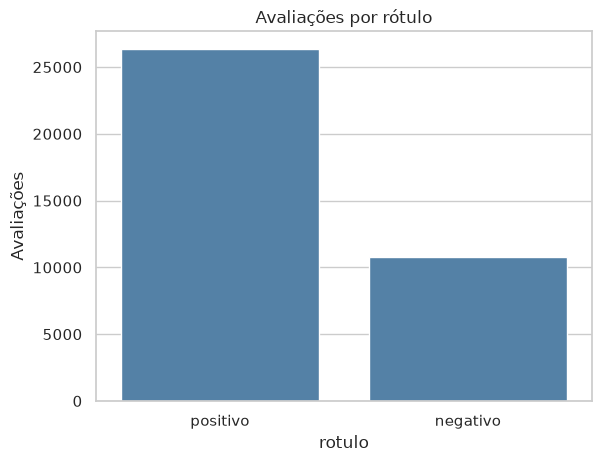

In [5]:
contagem = dados["rotulo"].value_counts()
print(contagem)
print(contagem / contagem.sum())
sns.barplot(x=contagem.index, y=contagem.values, color="steelblue")
plt.title("Avaliações por rótulo")
plt.ylabel("Avaliações")
plt.show()

**Conclusão:** há cerca de 71% de positivos contra 29% de negativos. Um modelo que chutasse sempre "positivo" acertaria ~71%, por isso olho também o **F1 macro** e uso `class_weight="balanced"` no baseline.

## 5. Tamanho dos textos

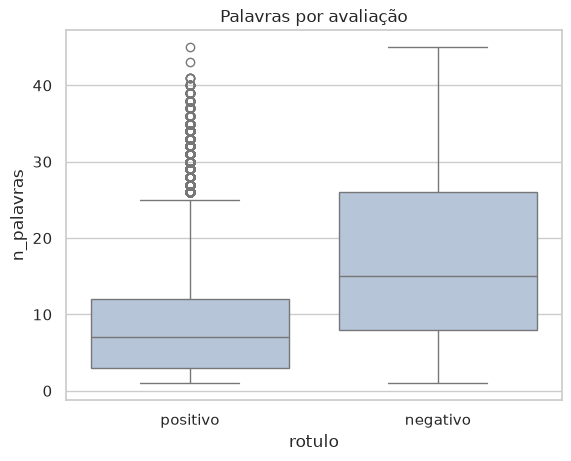

            count  mean   std  min  25%   50%   75%   max
rotulo                                                   
negativo  10758.0  17.4  10.6  1.0  8.0  15.0  26.0  45.0
positivo  26355.0   8.9   7.6  1.0  3.0   7.0  12.0  45.0


In [6]:
sns.boxplot(data=dados, x="rotulo", y="n_palavras", color="lightsteelblue")
plt.title("Palavras por avaliação")
plt.show()
print(dados.groupby("rotulo")["n_palavras"].describe().round(1))

**Conclusão:** avaliações negativas são mais longas (mediana de 15 palavras contra 7 nos positivos): quem reclama costuma explicar o problema.

## 6. Palavras mais comuns por classe

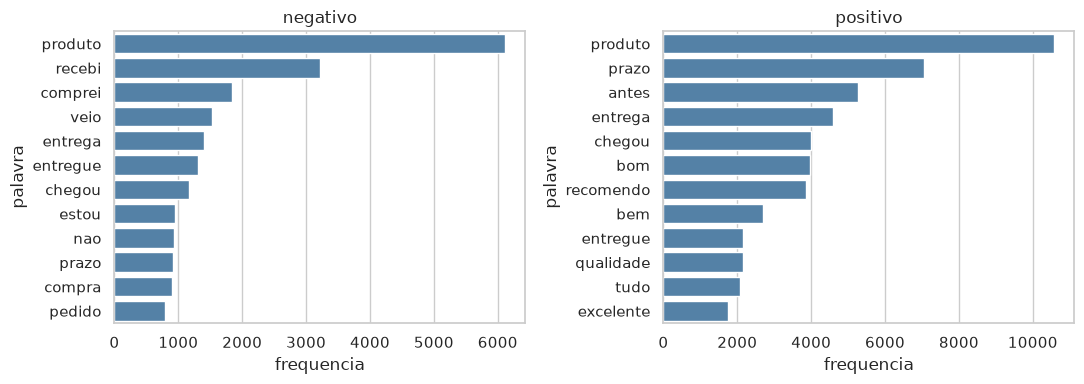

In [7]:
# lista curta de palavras sem significado (artigos, preposições...) para o gráfico ficar útil
parada = set("""a o e de da do que é em um uma para com não os as no na eu foi mas por se meu minha
muito ao já me mais ou só dos das pra nem como até tem pois isso ele ela seu sua nos mesmo ainda sem
entre há também""".split())

def palavras_comuns(textos, n=12):
    c = Counter(p for t in textos for p in re.findall(r"\w+", t) if p not in parada and len(p) > 2)
    return pd.DataFrame(c.most_common(n), columns=["palavra", "frequencia"])

fig, eixos = plt.subplots(1, 2, figsize=(11, 4))
for eixo, rotulo in zip(eixos, ["negativo", "positivo"]):
    top = palavras_comuns(dados.loc[dados["rotulo"] == rotulo, "texto"])
    sns.barplot(data=top, y="palavra", x="frequencia", color="steelblue", ax=eixo)
    eixo.set_title(rotulo)
plt.tight_layout()
plt.show()

**Conclusão:** "produto" e "entrega" aparecem nas duas classes, então só a palavra do tema não decide o sentimento. Termos como "recomendo", "bom" e "antes" (do prazo) pesam para o lado positivo; "recebi", "comprei", "veio" e "estou" aparecem muito nos negativos (relatos como "veio errado" ou "estou aguardando"); "não" foi tirado do gráfico como palavra comum, mas aparece nos coeficientes do baseline.